# 02 · Modelo de demanda por estación y hora

**Objetivo:** pronosticar cuántas bicis se van a **retirar** y **devolver** en cada estación durante la siguiente hora. La diferencia (`neto = arribos − retiros`) dice si la estación se va a vaciar o llenar.

**Por qué con viajes históricos:** la captura en AWS lleva pocos días, pero los viajes tienen dos meses de historia (septiembre y octubre de 2026). La demanda es lo que mueve la disponibilidad:

> bicis disponibles en 1 h ≈ bicis disponibles ahora + neto pronosticado

Esa conexión con los snapshots en vivo es el siguiente paso; aquí se valida que la demanda se puede pronosticar mejor que con reglas simples.

**Diseño de la evaluación:**
- División **temporal**: entrenamiento hasta el 17 de octubre, prueba del 18 al 31 (dos semanas que el modelo nunca vio).
- Solo **horario de operación** (fuera de 1:00 a 4:59).
- Dos baselines que el modelo debe superar: el **perfil histórico** por estación, tipo de día y hora, y **la misma hora de la semana pasada**.
- Métricas: MAE (error promedio en viajes), WAPE (error total relativo a la demanda total) y sesgo.

**Privacidad:** el módulo `trips` descarta edad y género al limpiar; el modelo solo usa conteos agregados por estación y hora.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ecobici import features, modeling, trips
from ecobici.http import get_json

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw_trips"
OUT = ROOT / "data" / "modelo"
OUT.mkdir(parents=True, exist_ok=True)

START, END = "2026-09-01", "2026-11-01"     # periodo analizado (hora local, END exclusivo)
TEST_START = "2026-10-18"                    # inicio del periodo de prueba

files = sorted(RAW.glob("*.csv"))
print(f"{len(files)} archivo(s):", [f.name for f in files])
assert files, f"No hay CSV en {RAW}"


2 archivo(s): ['public_data_web_2026-09.csv', 'public_data_web_2026-10.csv']


## 1. Carga y limpieza

In [2]:
t0 = time.time()
viajes = trips.clean(trips.load_many(files))
print(f"{len(viajes):,} viajes cargados en {time.time() - t0:.0f} s")
print(f"Válidos como demanda: {viajes['dq_ok'].mean():.2%}")
trips.quality_summary(viajes)


3,098,318 viajes cargados en 6 s
Válidos como demanda: 99.98%


,viajes,pct,invalida_demanda
dq_genero_no_reportado,78631,2.538,False
dq_viaje_menor_1min,447,0.014,True
dq_edad_atipica,106,0.003,False
dq_viaje_mayor_24h,61,0.002,True
dq_fecha_invalida,0,0.000,True
dq_arribo_antes_de_retiro,0,0.000,True
dq_misma_estacion_menor_2min,0,0.000,True
dq_duplicado,0,0.000,True


## 2. Malla estación × hora

Una fila por estación y hora, **incluidas las horas sin viajes** (en cero). Sin esto, el modelo solo vería las horas con demanda y sobreestimaría siempre.

In [3]:
malla = trips.hourly_counts(viajes, START, END)
n_est, n_horas = malla["station"].nunique(), malla["ts_hour"].nunique()
print(f"{n_est} estaciones × {n_horas:,} horas = {len(malla):,} filas")

op = malla[malla["en_horario"]]
print(f"Horas-estación con 0 retiros (en horario): {(op['retiros'] == 0).mean():.1%}")
print(f"Retiros promedio por estación-hora: {op['retiros'].mean():.2f}  (máx {op['retiros'].max()})")

validos = viajes[viajes["dq_ok"] & (viajes["ts_out"] >= START) & (viajes["ts_out"] < END)]
assert malla["retiros"].sum() == len(validos), "los conteos no cuadran con los viajes válidos"


676 estaciones × 1,464 horas = 989,664 filas
Horas-estación con 0 retiros (en horario): 22.8%
Retiros promedio por estación-hora: 3.76  (máx 295)


## 3. Clima histórico

Se descarga una vez del archivo histórico de Open-Meteo y se guarda en `data/clima_historico.parquet`. Si no hay internet, el notebook sigue sin clima (las columnas quedan vacías y el modelo las ignora).

In [4]:
CLIMA = ROOT / "data" / "clima_historico.parquet"
clima = None
if CLIMA.exists():
    clima = pd.read_parquet(CLIMA)
else:
    try:
        r = get_json("https://archive-api.open-meteo.com/v1/archive", params={
            "latitude": 19.4326, "longitude": -99.1332,
            "start_date": START, "end_date": (pd.Timestamp(END) - pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
            "hourly": "temperature_2m,precipitation",
            "timezone": "America/Mexico_City",          # misma hora local que los viajes
        })
        clima = pd.DataFrame(r["hourly"]).rename(columns={"time": "ts_hour"})
        clima["ts_hour"] = pd.to_datetime(clima["ts_hour"])
        clima.to_parquet(CLIMA, index=False)
    except Exception as e:
        print("Sin clima:", e)

if clima is not None:
    print(f"{len(clima):,} horas de clima; horas con lluvia (>0.5 mm): {(clima['precipitation'] > 0.5).sum()}")


1,464 horas de clima; horas con lluvia (>0.5 mm): 193


## 4. Features y división temporal

| Grupo | Features | Por qué |
|---|---|---|
| Calendario | hora, día de la semana, fin de semana, festivo, día laboral, quincena | La demanda tiene ciclos diarios y semanales muy marcados |
| Rezagos | misma estación hace 1 h, 24 h y 168 h; promedio de las 3 h previas | Capturan el nivel reciente de cada estación |
| Perfil | promedio histórico de la estación por tipo de día y hora (**solo con entrenamiento**) | Identidad de la estación sin fuga de información |
| Clima | temperatura, lluvia, llueve (>0.5 mm) | La lluvia reduce la demanda |

Los rezagos se calculan sobre la malla de 24 horas y después se filtra el horario de operación, para que "hace 24 h" sea exactamente la misma hora del día anterior.

In [5]:
df = features.add_calendar(malla.copy())
df = features.add_lags(df)
df = features.add_weather(df, clima)

train, test = modeling.temporal_split(df, TEST_START)
perfil = features.station_profile(train)
train = features.add_profile(train, perfil)
test = features.add_profile(test, perfil)

# Solo horario de operación; se descarta la primera semana de entrenamiento (sin rezago de 168 h).
train = train[train["en_horario"] & train["retiros_lag_168h"].notna()]
test = test[test["en_horario"]]
print(f"Entrenamiento: {train['ts_hour'].min():%d/%m} a {train['ts_hour'].max():%d/%m}, {len(train):,} filas")
print(f"Prueba:        {test['ts_hour'].min():%d/%m} a {test['ts_hour'].max():%d/%m}, {len(test):,} filas")


Entrenamiento: 08/09 a 17/10, 540,800 filas
Prueba:        18/10 a 31/10, 189,280 filas


## 5. Baselines y modelo

- **Perfil histórico:** lo que la estación hace "normalmente" a esa hora en ese tipo de día.
- **Semana pasada:** lo que pasó exactamente 168 h antes.
- **Gradient boosting (Poisson):** `HistGradientBoostingRegressor` con pérdida Poisson, adecuada para conteos (no negativos, muchos ceros, sesgados). Un modelo para retiros y otro para arribos.

In [6]:
preds = {"retiros": {}, "arribos": {}}
modelos = {}
for target in ["retiros", "arribos"]:
    preds[target]["Perfil histórico"] = test[f"{target}_perfil"].fillna(0)
    preds[target]["Semana pasada"] = test[f"{target}_lag_168h"].fillna(0)
    t0 = time.time()
    modelos[target] = modeling.fit_hgb(train, target)
    preds[target]["Gradient boosting"] = modeling.predict(modelos[target], test)
    print(f"{target}: entrenado en {time.time() - t0:.0f} s, {modelos[target].n_iter_} iteraciones")

# Neto pronosticado = arribos − retiros de cada método.
test["neto"] = test["arribos"] - test["retiros"]
preds["neto"] = {m: preds["arribos"][m] - preds["retiros"][m] for m in preds["retiros"]}


retiros: entrenado en 9 s, 400 iteraciones
arribos: entrenado en 8 s, 400 iteraciones


## 6. Evaluación

Tres segmentos:
- **Todas:** todas las estaciones en horario de operación.
- **Hora pico laboral:** 7–9 h y 17–19 h en días laborales, cuando el rebalanceo importa.
- **Estaciones con más desbalance:** las 10 con mayor neto promedio (en valor absoluto) en las mañanas laborales del entrenamiento.

In [7]:
manana = train[train["dia_laboral"] & train["hora"].between(6, 10)]
top_desbalance = manana.groupby("station")["neto"].mean().abs().nlargest(10).index
print("Estaciones con más desbalance:", list(top_desbalance))

segmentos = {
    "Todas": pd.Series(True, index=test.index),
    "Hora pico laboral": test["hora_pico"],
    "Top 10 desbalance": test["station"].isin(top_desbalance),
}
tablas = {t: modeling.evaluate(test, preds[t], t, segmentos) for t in ["retiros", "arribos", "neto"]}
resultados = pd.concat({t: tab for t, tab in tablas.items()}, names=["objetivo"]).reset_index(level=0)
resultados.to_csv(OUT / "metricas.csv", index=False)

resultados.pivot_table(index=["objetivo", "modelo"], columns="segmento", values="MAE").round(3)


Estaciones con más desbalance: ['271-272', '266-267', '014', '273-274', '208', '018', '474', '242', '217', '548']


segmento                    Hora pico laboral  Todas  Top 10 desbalance
objetivo modelo                                                        
arribos  Gradient boosting              2.230  1.664              4.303
         Perfil histórico               2.554  1.862              4.723
         Semana pasada                  3.250  2.360              5.646
neto     Gradient boosting              2.730  1.910              5.795
         Perfil histórico               2.873  1.964              6.134
         Semana pasada                  3.642  2.591              6.872
retiros  Gradient boosting              2.502  1.724              4.175
         Perfil histórico               2.908  1.964              4.819
         Semana pasada                  3.666  2.493              5.549

In [8]:
# WAPE (no aplica al neto, que puede sumar cero)
resultados[resultados["objetivo"] != "neto"].pivot_table(
    index=["objetivo", "modelo"], columns="segmento", values="WAPE_%").round(1)


segmento                    Hora pico laboral  Todas  Top 10 desbalance
objetivo modelo                                                        
arribos  Gradient boosting             34.500 42.300             31.500
         Perfil histórico              39.500 47.300             34.600
         Semana pasada                 50.300 60.000             41.300
retiros  Gradient boosting             38.800 43.800             37.400
         Perfil histórico              45.100 49.900             43.200
         Semana pasada                 56.900 63.300             49.700

In [9]:
def mejora(objetivo, segmento):
    t = resultados[(resultados["objetivo"] == objetivo) & (resultados["segmento"] == segmento)].set_index("modelo")["MAE"]
    base = t.drop("Gradient boosting").min()
    return (1 - t["Gradient boosting"] / base) * 100, t.drop("Gradient boosting").idxmin()

print("Mejora del modelo en MAE contra el mejor baseline:")
for obj in ["retiros", "arribos", "neto"]:
    for seg in segmentos:
        pct, base = mejora(obj, seg)
        print(f"  {obj:<8} {seg:<20} {pct:+6.1f}%  (vs {base})")


Mejora del modelo en MAE contra el mejor baseline:
  retiros  Todas                 +12.3%  (vs Perfil histórico)
  retiros  Hora pico laboral     +14.0%  (vs Perfil histórico)
  retiros  Top 10 desbalance     +13.4%  (vs Perfil histórico)
  arribos  Todas                 +10.7%  (vs Perfil histórico)
  arribos  Hora pico laboral     +12.7%  (vs Perfil histórico)
  arribos  Top 10 desbalance      +8.9%  (vs Perfil histórico)
  neto     Todas                  +2.8%  (vs Perfil histórico)
  neto     Hora pico laboral      +5.0%  (vs Perfil histórico)
  neto     Top 10 desbalance      +5.5%  (vs Perfil histórico)


## 7. Pronóstico contra lo real en una estación con desbalance

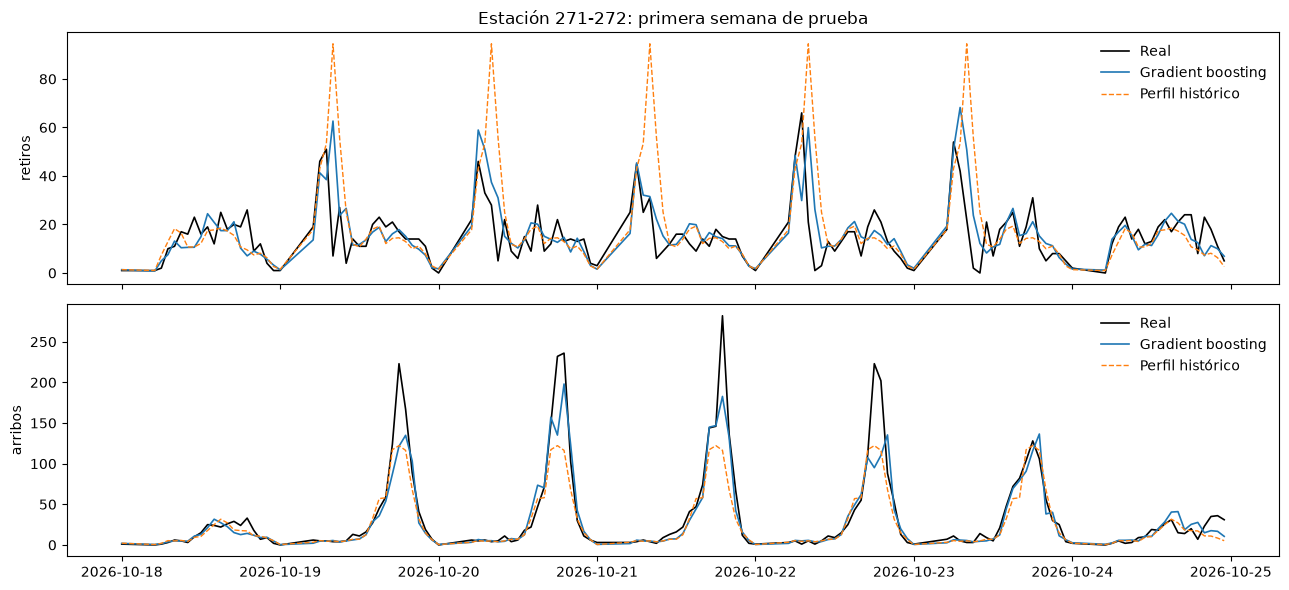

In [10]:
est = top_desbalance[0]
semana = test[(test["station"] == est) & (test["ts_hour"] < pd.Timestamp(TEST_START) + pd.Timedelta(days=7))]
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for ax, target in zip(axes, ["retiros", "arribos"]):
    ax.plot(semana["ts_hour"], semana[target], color="black", lw=1.2, label="Real")
    ax.plot(semana["ts_hour"], preds[target]["Gradient boosting"][semana.index], lw=1.2, label="Gradient boosting")
    ax.plot(semana["ts_hour"], preds[target]["Perfil histórico"][semana.index], lw=1, ls="--", label="Perfil histórico")
    ax.set_ylabel(target)
    ax.legend(loc="upper right", frameon=False)
axes[0].set_title(f"Estación {est}: primera semana de prueba")
plt.tight_layout()
plt.show()


## 8. ¿Qué aprendió el modelo?

Importancia por permutación: cuánto empeora el MAE si se revuelve una feature. Se calcula sobre una muestra del periodo de prueba.

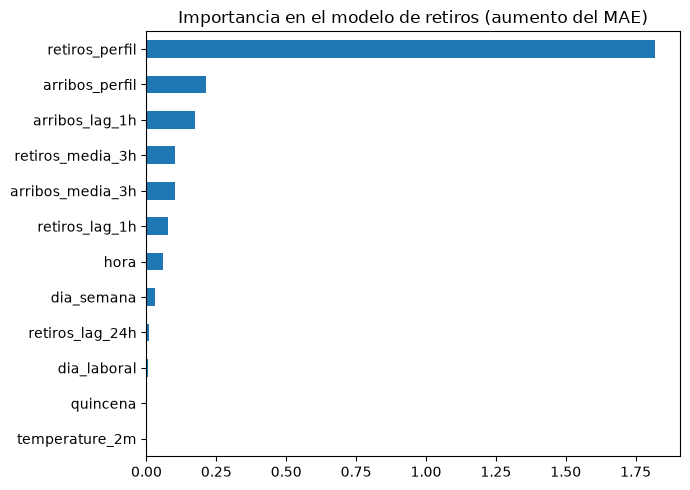

In [11]:
from sklearn.inspection import permutation_importance

muestra = test.sample(min(30_000, len(test)), random_state=0)
imp = permutation_importance(
    modelos["retiros"], muestra[modeling.FEATURES].astype("float32"), muestra["retiros"],
    scoring="neg_mean_absolute_error", n_repeats=3, random_state=0)
importancia = pd.Series(imp.importances_mean, index=modeling.FEATURES).sort_values()
importancia.tail(12).plot.barh(figsize=(7, 5), title="Importancia en el modelo de retiros (aumento del MAE)")
plt.tight_layout()
plt.show()


## 9. Conclusiones y siguientes pasos

Completar con los resultados de las celdas anteriores:

- **¿El modelo supera a los baselines?** Ver la tabla de mejora (sección 6). Lo importante es el segmento de hora pico y el de estaciones con desbalance.
- **¿Qué features pesan más?** Ver la sección 8. Si el perfil y los rezagos dominan, la estación y su historia reciente explican casi todo. Si la lluvia aparece, el clima suma valor.
- **¿Hay sesgo?** Un sesgo negativo en hora pico significa que el modelo subestima la demanda justo cuando más importa.

**Siguientes pasos:**
1. Convertir la demanda pronosticada en disponibilidad: `bicis_en_1h = bicis_ahora + neto_pronosticado`, acotado entre 0 y la capacidad, usando los snapshots de AWS.
2. Validar esa disponibilidad contra los snapshots reales cuando haya dos semanas de captura.
3. Empaquetar el modelo para la Lambda de inferencia.

**Fuera de alcance de este notebook:** optimización de rutas de rebalanceo y ajuste fino de hiperparámetros.

In [12]:
resultados[resultados["modelo"] == "Gradient boosting"].pivot_table(
    index="objetivo", columns="segmento", values="sesgo").round(3)

segmento,Hora pico laboral,Todas,Top 10 desbalance
objetivo,,,
arribos,-0.112,-0.156,-0.380
neto,0.001,0.017,0.179
retiros,-0.113,-0.173,-0.558


In [13]:
# Tabla de estaciones con más desbalance para el perfil funcional (sin datos personales)
cat_files = sorted((ROOT / "data" / "silver" / "dim_station").rglob("*.parquet"))
cat = pd.read_parquet(cat_files[-1])[["short_name", "name", "lat", "lon", "capacity"]]

lab = train[train["dia_laboral"]]
neto_manana = lab[lab["hora"].between(6, 10)].groupby("station")["neto"].mean().rename("neto_manana_por_hora")
neto_tarde = lab[lab["hora"].between(16, 20)].groupby("station")["neto"].mean().rename("neto_tarde_por_hora")
retiros_dia = (lab.groupby(["station", lab["ts_hour"].dt.date])["retiros"].sum()
                  .groupby("station").mean().rename("retiros_por_dia_laboral"))

t = pd.concat([neto_manana, neto_tarde, retiros_dia], axis=1)
t["patron"] = np.where(t["neto_manana_por_hora"] < 0, "Se vacía en la mañana", "Se llena en la mañana")
top = (t.reindex(t["neto_manana_por_hora"].abs().sort_values(ascending=False).index).head(20)
         .reset_index().rename(columns={"station": "short_name"})
         .merge(cat, on="short_name", how="left"))
top["mapa"] = "https://www.google.com/maps?q=" + top["lat"].astype(str) + "," + top["lon"].astype(str)
for col in ["colonia", "que_hay_cerca", "hipotesis"]:
    top[col] = ""

top = top.round(2)
top.to_csv(OUT / "estaciones_desbalance.csv", index=False)
print(f"Guardado en {OUT / 'estaciones_desbalance.csv'}")
top

Guardado en /Users/ivonneorio/Documents/MCD/Cómputo en la Nube/ecobici-cloud/data/modelo/estaciones_desbalance.csv


,short_name,neto_manana_por_hora,neto_tarde_por_hora,retiros_por_dia_laboral,patron,name,lat,lon,capacity,mapa,colonia,que_hay_cerca,hipotesis
0,271-272,-47.540,85.100,440.040,Se vacía en la mañana,CE-271-272 Jesús García - Carlos J. Meneses,19.440,-99.150,74,"https://www.google.com/maps?q=19.443684,-99.15...",,,
1,266-267,-22.520,32.740,194.640,Se vacía en la mañana,CE-266-267 Jesús García - Carlos J. Meneses,19.440,-99.150,75,"https://www.google.com/maps?q=19.444031,-99.15...",,,
2,014,19.890,-7.910,221.070,Se llena en la mañana,CE-014 Reforma - Río de Plata,19.420,-99.170,39,"https://www.google.com/maps?q=19.42454,-99.173247",,,
3,273-274,-17.890,22.460,157.250,Se vacía en la mañana,CE-273-274 Luis Donaldo Colosio - Av. Jesús Ga...,19.440,-99.150,70,"https://www.google.com/maps?q=19.442707,-99.15...",,,
4,208,-14.440,2.580,308.250,Se vacía en la mañana,CE-208 Hesiodo-Lamartine,19.430,-99.190,25,"https://www.google.com/maps?q=19.434182,-99.18...",,,
5,018,14.380,-6.660,223.500,Se llena en la mañana,CE-018 Reforma - Río Rhin,19.430,-99.160,39,"https://www.google.com/maps?q=19.428802,-99.16...",,,
6,474,13.940,-6.110,149.000,Se llena en la mañana,CE-474 Bahía de San Hipólito-Bahía del Espírit...,19.440,-99.180,31,"https://www.google.com/maps?q=19.438984,-99.17...",,,
7,242,13.780,-3.100,195.710,Se llena en la mañana,CE-242 Pról. Moliere-Miguel de Cervantes Saavedra,19.440,-99.200,31,https://www.google.com/maps?q=19.4400267209081...,,,
8,217,12.990,-4.890,147.460,Se llena en la mañana,CE-217 Euler-Horacio,19.430,-99.180,31,https://www.google.com/maps?q=19.4328509195364...,,,
9,548,-12.280,14.950,343.320,Se vacía en la mañana,CE-548 Dr. Mariano Azuela - Jose Antonio Alzate,19.450,-99.150,39,https://www.google.com/maps?q=19.4470289030880...,,,
